# 03 — Baseline de média móvel e protocolo de avaliação

Etapa 5 da Fase 1. Previsão da semana *t* = média das 4 semanas que terminam em *t − 1*
(`src/pipeline/baseline.py`). Teste = últimas 52 semanas, com origem móvel.
**k = 4 foi fixado antes**; k = 1, 8 e 13 aparecem só como sensibilidade.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.2f}".format

from pipeline.baseline import moving_average_forecast
from pipeline.config import SELECTED_SERIES, SENSITIVITY_WINDOWS, MA_WINDOW
from pipeline.data import load_train
from pipeline.evaluation import evaluate, test_period
from pipeline.weekly import select_series, to_weekly

weekly = select_series(to_weekly(load_train()), SELECTED_SERIES)
weekly["forecast"] = moving_average_forecast(weekly, window=MA_WINDOW, horizon=1)
per_series, residuals = evaluate(weekly)
period = test_period(weekly)
print(f"teste: {period[0].date()} a {period[-1].date()} ({len(period)} semanas)")
per_series

teste: 2016-08-15 a 2017-08-07 (52 semanas)


,store_nbr,family,mae,mape,mape_ignored,wape,bias,points
0,44,BEVERAGES,"6,882.13",9.02,0,9.09,-0.48,52
1,44,BREAD/BAKERY,"1,013.12",8.37,0,8.17,-0.27,52
2,44,DAIRY,"1,317.62",6.53,0,6.51,-0.05,52
3,44,GROCERY I,"6,931.88",8.71,0,8.91,-0.27,52
4,54,BEVERAGES,"2,574.11",14.02,0,16.19,-3.95,52
5,54,BREAD/BAKERY,135.33,9.13,0,8.82,-0.41,52
6,54,DAIRY,146.26,7.77,0,7.90,0.04,52
7,54,GROCERY I,"2,283.03",9.60,0,10.19,-0.66,52


## 1. Como ler

- **MAE** está na unidade da série: não compara a loja 44 (68 mil/semana) com a 54 (1,3 mil).
- **MAPE** é percentual e comparável. Faz sentido tirar a média dele entre séries; a média do MAE seria dominada pelas séries grandes.
- **WAPE** e **viés** usam a mesma definição do simulador do app.

In [2]:
print(f"MAPE médio das séries: {per_series.mape.mean():.2f}% | WAPE médio: {per_series.wape.mean():.2f}% | viés médio: {per_series.bias.mean():+.2f}%")

MAPE médio das séries: 9.14% | WAPE médio: 9.47% | viés médio: -0.76%


## 2. Sensibilidade a k (só análise: escolher k no teste seria calibrar no teste)

In [3]:
rows = []
for k in (1, MA_WINDOW, *[w for w in SENSITIVITY_WINDOWS if w != 1]):
    w = weekly.assign(forecast=moving_average_forecast(weekly, window=k, horizon=1))
    ps, _ = evaluate(w)
    rows.append({"k": k, "MAPE médio": ps.mape.mean(), "WAPE médio": ps.wape.mean()})
pd.DataFrame(rows).set_index("k")

,MAPE médio,WAPE médio
k,,
1,10.10,10.48
4,9.14,9.47
8,9.40,9.75
13,9.56,10.05


## 3. Real × previsto no período de teste

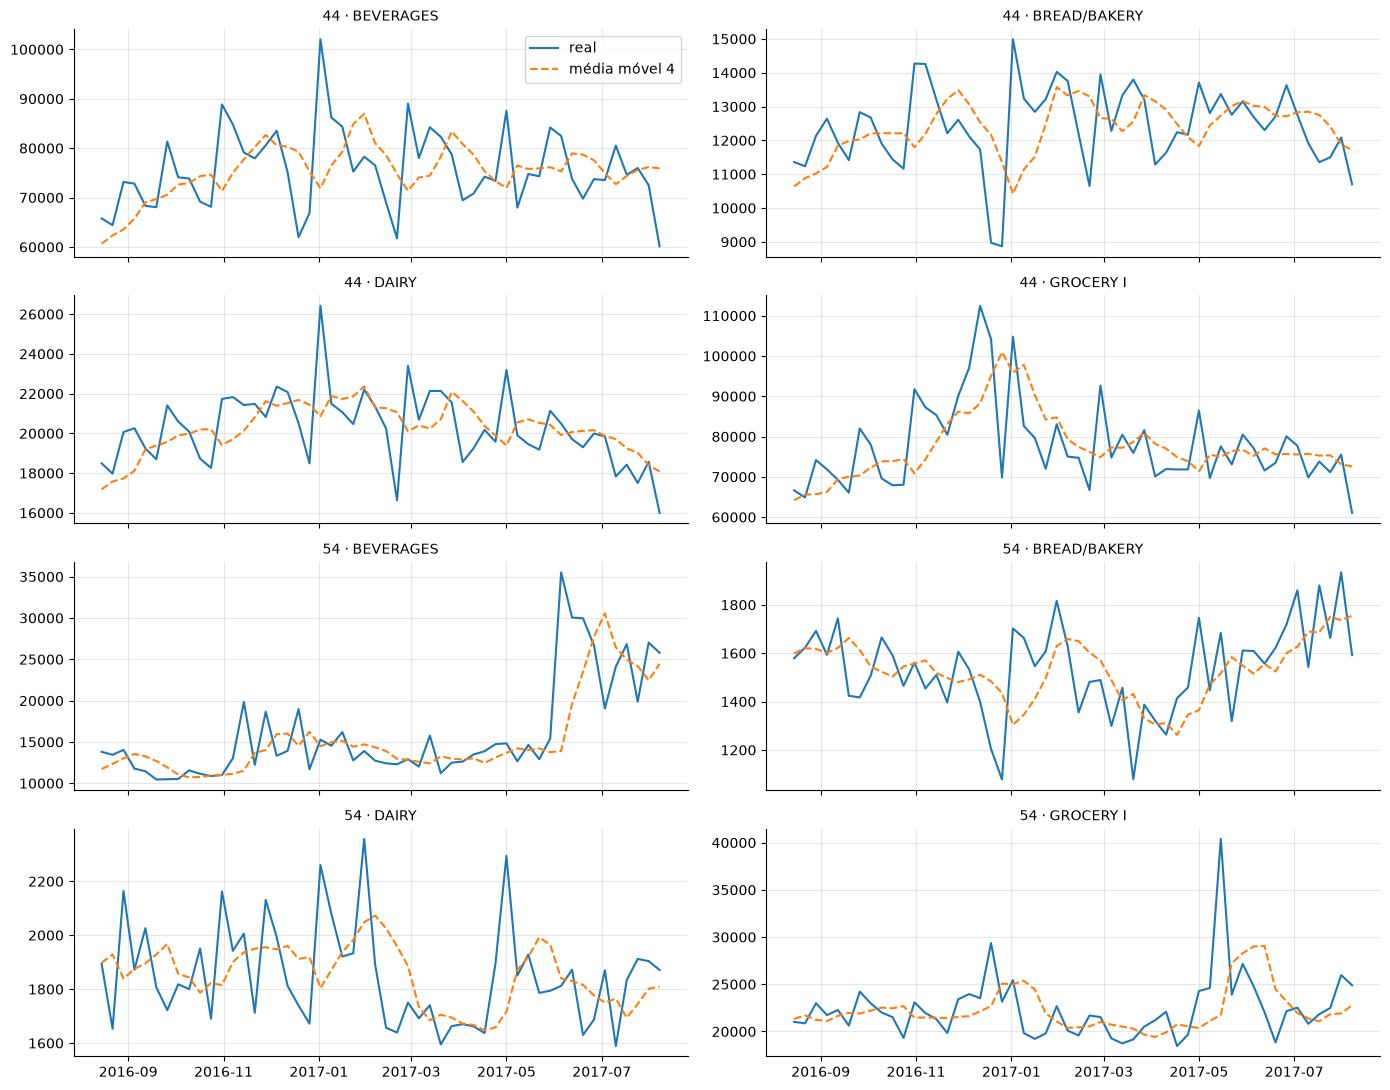

In [4]:
fig, axes = plt.subplots(4, 2, figsize=(14, 11), sharex=True)
for ax, (key, s) in zip(axes.flat, weekly[weekly.week_start.isin(period)].groupby(["store_nbr", "family"], observed=True)):
    ax.plot(s.week_start, s.sales, label="real", lw=1.5)
    ax.plot(s.week_start, s.forecast, label="média móvel 4", lw=1.5, ls="--")
    ax.set_title(f"{key[0]} · {key[1]}", fontsize=10)
axes[0, 0].legend(); plt.tight_layout(); plt.show()

## 4. Onde a média móvel erra

O esperado: os maiores erros perto do Natal e do Ano-Novo, porque a média móvel não sabe que dezembro é diferente e chega atrasada a qualquer mudança de nível.

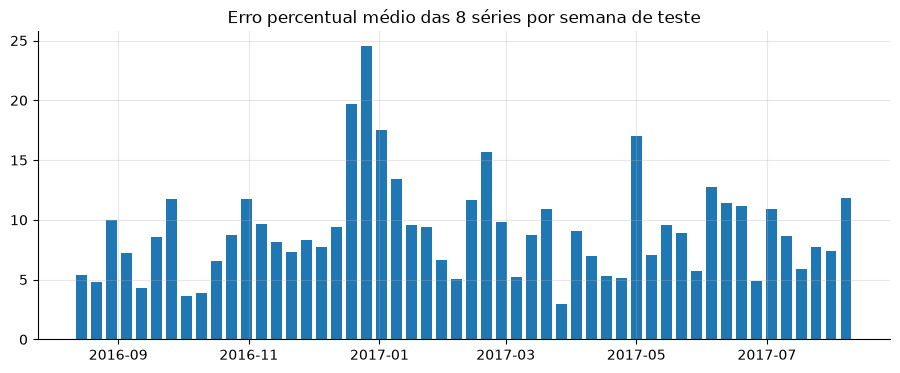

,MAPE da semana (%)
week_start,
2016-12-26,24.54
2016-12-19,19.67
2017-01-02,17.52
2017-05-01,17.03
2017-02-20,15.66


In [5]:
residuals["ape"] = (residuals.error.abs() / residuals.sales) * 100
by_week = residuals.groupby("week_start").ape.mean()
fig, ax = plt.subplots()
ax.bar(by_week.index, by_week.values, width=5)
ax.set_title("Erro percentual médio das 8 séries por semana de teste"); plt.show()
by_week.sort_values(ascending=False).head(5).to_frame("MAPE da semana (%)")

**Conclusão:** a média móvel de 4 semanas erra em torno de 9% (MAPE) nessas 8 séries, e os piores momentos são as viradas de ano. Essa é a régua da Fase 2. No app, o modelo LightGBM foi comparado com essa mesma média móvel em todas as 1.729 séries do Favorita, por faixa de volume (página `/modelo`).